# Credit Risk — Data Loading, Quality Checks, Statistics & EDA

**Dataset:** `credit_risk_dataset.csv` — one row per loan applicant.
**Target:** `loan_status` (1 = default, 0 = repaid).

**Contents**
1. Setup & load data
2. Data overview
3. Data quality: missing values, duplicates, impossible values
4. Statistical analysis
5. Exploratory data analysis (EDA)
6. Key findings

## 1. Setup & load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

# Plot style: thin, quiet axes; blue = repaid, orange = default
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
STATUS_COLORS = {0: BLUE, 1: ORANGE}
STATUS_LABELS = {0: "Repaid (0)", 1: "Default (1)"}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_orange", [BLUE, "#e8e7e3", ORANGE])

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d0cfca", "grid.color": "#ebeae6", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
    "figure.dpi": 110,
})

In [2]:
df_raw = pd.read_csv("credit_risk_dataset.csv")
print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Shape: 32,581 rows x 12 columns


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.000,PERSONAL,D,35000,16.020,1,0.590,Y,3
1,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0,0.100,N,2
2,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,1,0.570,N,3
3,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,1,0.530,N,2
4,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,1,0.550,Y,4


## 2. Data overview

| Column | Meaning |
|---|---|
| `person_age` | Applicant age |
| `person_income` | Annual income |
| `person_home_ownership` | RENT / OWN / MORTGAGE / OTHER |
| `person_emp_length` | Employment length (years) |
| `loan_intent` | Purpose of the loan |
| `loan_grade` | Lender-assigned grade, A (best) → G (worst) |
| `loan_amnt` | Loan amount |
| `loan_int_rate` | Interest rate (%) |
| `loan_status` | **Target** — 1 = default |
| `loan_percent_income` | Loan amount / income |
| `cb_person_default_on_file` | Previous default on credit bureau file (Y/N) |
| `cb_person_cred_hist_length` | Credit history length (years) |

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
num_cols = df_raw.select_dtypes(include="number").columns.drop("loan_status").tolist()
cat_cols = df_raw.select_dtypes(include="object").columns.tolist()
print("Numeric:    ", num_cols)
print("Categorical:", cat_cols)
df_raw[cat_cols].nunique()

Numeric:     ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


person_home_ownership        4
loan_intent                  6
loan_grade                   7
cb_person_default_on_file    2
dtype: int64

## 3. Data quality
### 3.1 Missing values

In [5]:
missing = (
    df_raw.isna().sum().to_frame("n_missing")
    .assign(pct_missing=lambda t: 100 * t.n_missing / len(df_raw))
    .query("n_missing > 0")
    .sort_values("n_missing", ascending=False)
)
missing

,n_missing,pct_missing
loan_int_rate,3116,9.564
person_emp_length,895,2.747


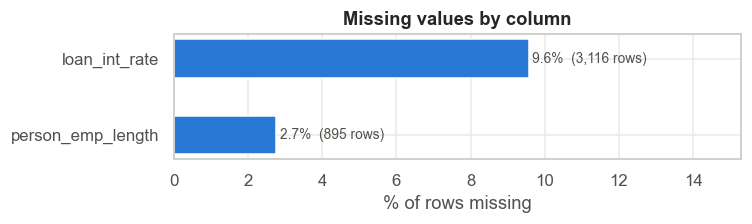

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(missing.index, missing.pct_missing, color=BLUE, height=0.5)
for y, (n, p) in enumerate(zip(missing.n_missing, missing.pct_missing)):
    ax.text(p + 0.1, y, f"{p:.1f}%  ({n:,} rows)", va="center", color=GRAY, fontsize=9)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column")
ax.set_xlim(0, missing.pct_missing.max() * 1.6)
ax.invert_yaxis()
plt.tight_layout(); plt.show()

Is missingness random? Compare the default rate for rows where the value is missing vs present.

In [7]:
pd.DataFrame({
    col: df_raw.groupby(df_raw[col].isna())["loan_status"].mean()
    for col in missing.index
}).rename(index={False: "default rate | present", True: "default rate | missing"})

,loan_int_rate,person_emp_length
default rate | present,0.219,0.215
default rate | missing,0.207,0.315


### 3.2 Duplicates

In [8]:
n_dup = df_raw.duplicated().sum()
print(f"Fully duplicated rows: {n_dup:,} ({100 * n_dup / len(df_raw):.2f}%)")

Fully duplicated rows: 165 (0.51%)


### 3.3 Impossible / extreme values

In [9]:
checks = {
    "age > 100": df_raw.person_age > 100,
    "emp_length > 60 years": df_raw.person_emp_length > 60,
    "emp_length > age": df_raw.person_emp_length > df_raw.person_age,
    "income > 1M": df_raw.person_income > 1_000_000,
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="n_rows").to_frame()

,n_rows
age > 100,5
emp_length > 60 years,2
emp_length > age,2
income > 1M,9


In [10]:
df_raw.loc[checks["age > 100"] | checks["emp_length > 60 years"],
           ["person_age", "person_emp_length", "person_income", "loan_amnt", "loan_status"]]

,person_age,person_emp_length,person_income,loan_amnt,loan_status
0,22,123.000,59000,35000,1
81,144,4.000,250000,4800,0
183,144,4.000,200000,6000,0
210,21,123.000,192000,20000,0
575,123,2.000,80004,20400,0
747,123,7.000,78000,20000,0
32297,144,12.000,6000000,5000,0


### 3.4 Cleaned dataset used for analysis

- Drop exact duplicate rows.
- Drop rows with impossible values (age > 100, employment length > 60 years).
- **Missing values are kept as NaN** for EDA (statistics below skip NaNs). Imputation — e.g. the
  median by `loan_grade` for `loan_int_rate` — is a modelling decision and belongs in a later step.

In [11]:
df = (
    df_raw.drop_duplicates()
    .loc[lambda d: ~((d.person_age > 100) | (d.person_emp_length > 60))]
    .reset_index(drop=True)
)
print(f"Raw: {len(df_raw):,} rows  ->  Clean: {len(df):,} rows  (removed {len(df_raw) - len(df):,})")

Raw: 32,581 rows  ->  Clean: 32,409 rows  (removed 172)


## 4. Statistical analysis
### 4.1 Descriptive statistics — numeric

In [12]:
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
person_age,"32,409.000",27.731,6.210,20.000,23.000,26.000,30.000,94.000,1.942,5.867
person_income,"32,409.000","65,894.277","52,517.870","4,000.000","38,500.000","55,000.000","79,200.000","2,039,784.000",9.778,226.086
person_emp_length,"31,522.000",4.783,4.037,0.000,2.000,4.000,7.000,41.000,1.250,2.420
loan_amnt,"32,409.000","9,592.487","6,320.885",500.000,"5,000.000","8,000.000","12,250.000","35,000.000",1.191,1.420
loan_int_rate,"29,315.000",11.017,3.242,5.420,7.900,10.990,13.470,23.220,0.207,-0.673
loan_percent_income,"32,409.000",0.170,0.107,0.000,0.090,0.150,0.230,0.830,1.063,1.215
cb_person_cred_hist_length,"32,409.000",5.811,4.058,2.000,3.000,4.000,8.000,30.000,1.658,3.699


### 4.2 Descriptive statistics — categorical

In [13]:
df[cat_cols].describe().T

,count,unique,top,freq
person_home_ownership,32409,4,RENT,16374
loan_intent,32409,6,EDUCATION,6409
loan_grade,32409,7,A,10702
cb_person_default_on_file,32409,2,N,26680


### 4.3 Target balance

In [14]:
target = df.loan_status.value_counts().to_frame("count")
target["pct"] = 100 * target["count"] / len(df)
target.rename(index=STATUS_LABELS)

,count,pct
loan_status,,
Repaid (0),25321,78.130
Default (1),7088,21.870


### 4.4 Numeric features vs target — Mann–Whitney U test

Numeric features are heavily skewed, so we compare defaulters vs non-defaulters with the
non-parametric **Mann–Whitney U** test (H₀: both groups have the same distribution).
Effect size is the **rank-biserial correlation** r (−1…1; |r| ≈ 0.1 small, 0.3 medium, 0.5 large).

In [15]:
rows = []
for col in num_cols:
    g0 = df.loc[df.loan_status == 0, col].dropna()
    g1 = df.loc[df.loan_status == 1, col].dropna()
    u, p = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    rows.append({
        "feature": col,
        "median_repaid": g0.median(),
        "median_default": g1.median(),
        "U": u,
        "p_value": p,
        "rank_biserial_r": 2 * u / (len(g0) * len(g1)) - 1,
    })
mw = pd.DataFrame(rows).set_index("feature").sort_values("rank_biserial_r", key=abs, ascending=False)
mw.style.format({"p_value": "{:.1e}", "U": "{:,.0f}"}, precision=3)

,median_repaid,median_default,U,p_value,rank_biserial_r
feature,,,,,
loan_int_rate,10.590,13.490,"106,680,194",0.0e+00,0.447
loan_percent_income,0.130,0.240,"129,380,805",0.0e+00,0.442
person_income,60000.000,41655.000,"55,628,999",0.0e+00,-0.380
person_emp_length,4.000,3.000,"72,609,117",1.0e-67,-0.137
loan_amnt,8000.000,9600.000,"100,310,488",3.7e-52,0.118
person_age,26.000,26.000,"85,426,174",5.2e-10,-0.048
cb_person_cred_hist_length,4.000,4.000,"86,642,414",7.1e-06,-0.034


### 4.5 Categorical features vs target — Chi-square test of independence

H₀: the feature and `loan_status` are independent. Effect size is **Cramér's V** (0…1).

In [16]:
rows = []
for col in cat_cols:
    table = pd.crosstab(df[col], df.loan_status)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"feature": col, "chi2": chi2, "dof": dof, "p_value": p, "cramers_v": cramers_v})
chi = pd.DataFrame(rows).set_index("feature").sort_values("cramers_v", ascending=False)
chi.style.format({"p_value": "{:.1e}"}, precision=3)

,chi2,dof,p_value,cramers_v
feature,,,,
loan_grade,5584.784,6,0.0e+00,0.415
person_home_ownership,1893.770,3,0.0e+00,0.242
cb_person_default_on_file,1040.119,1,3.4e-228,0.179
loan_intent,519.625,5,4.6e-110,0.127


### 4.6 Correlation (Spearman) between numeric features and the target

In [17]:
corr = df[num_cols + ["loan_status"]].corr(method="spearman")
corr["loan_status"].drop("loan_status").sort_values(key=abs, ascending=False).to_frame("spearman_vs_target")

,spearman_vs_target
loan_int_rate,0.321
loan_percent_income,0.316
person_income,-0.272
person_emp_length,-0.098
loan_amnt,0.084
person_age,-0.035
cb_person_cred_hist_length,-0.025


## 5. Exploratory data analysis
### 5.1 Target distribution

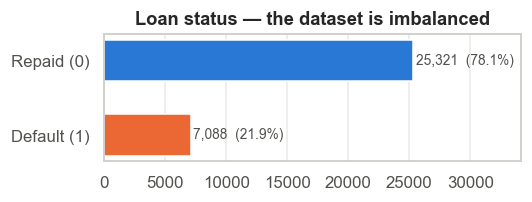

In [18]:
fig, ax = plt.subplots(figsize=(5, 2))
counts = df.loan_status.value_counts().sort_index()
ax.barh([STATUS_LABELS[i] for i in counts.index], counts.values,
        color=[STATUS_COLORS[i] for i in counts.index], height=0.55)
for y, c in enumerate(counts.values):
    ax.text(c + 200, y, f"{c:,}  ({100 * c / counts.sum():.1f}%)", va="center", color=GRAY, fontsize=9)
ax.set_xlim(0, counts.max() * 1.35)
ax.set_title("Loan status — the dataset is imbalanced")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 5.2 Numeric distributions by loan status
Income and loan amount are shown on a log scale because of their long right tails.

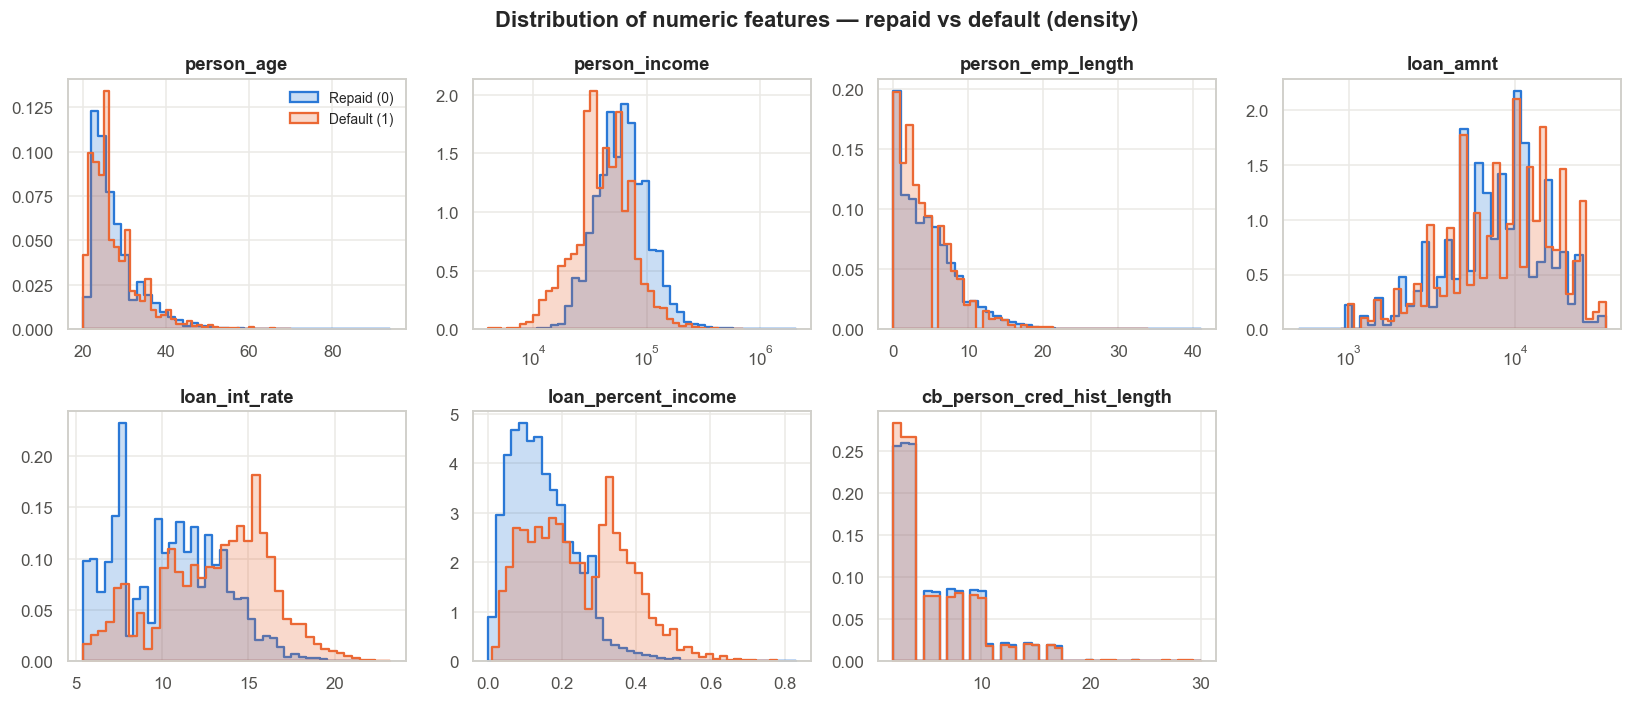

In [19]:
log_cols = {"person_income", "loan_amnt"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.flat, num_cols):
    for status in (0, 1):
        sns.histplot(
            df.loc[df.loan_status == status, col].dropna(), ax=ax, bins=40, stat="density",
            element="step", fill=True, alpha=0.25, linewidth=1.5,
            color=STATUS_COLORS[status], label=STATUS_LABELS[status], log_scale=col in log_cols,
        )
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
axes.flat[0].legend(frameon=False, fontsize=9)
for ax in axes.flat[len(num_cols):]:
    ax.remove()
fig.suptitle("Distribution of numeric features — repaid vs default (density)", fontweight="bold")
plt.tight_layout(); plt.show()

### 5.3 Outliers — boxplots by loan status

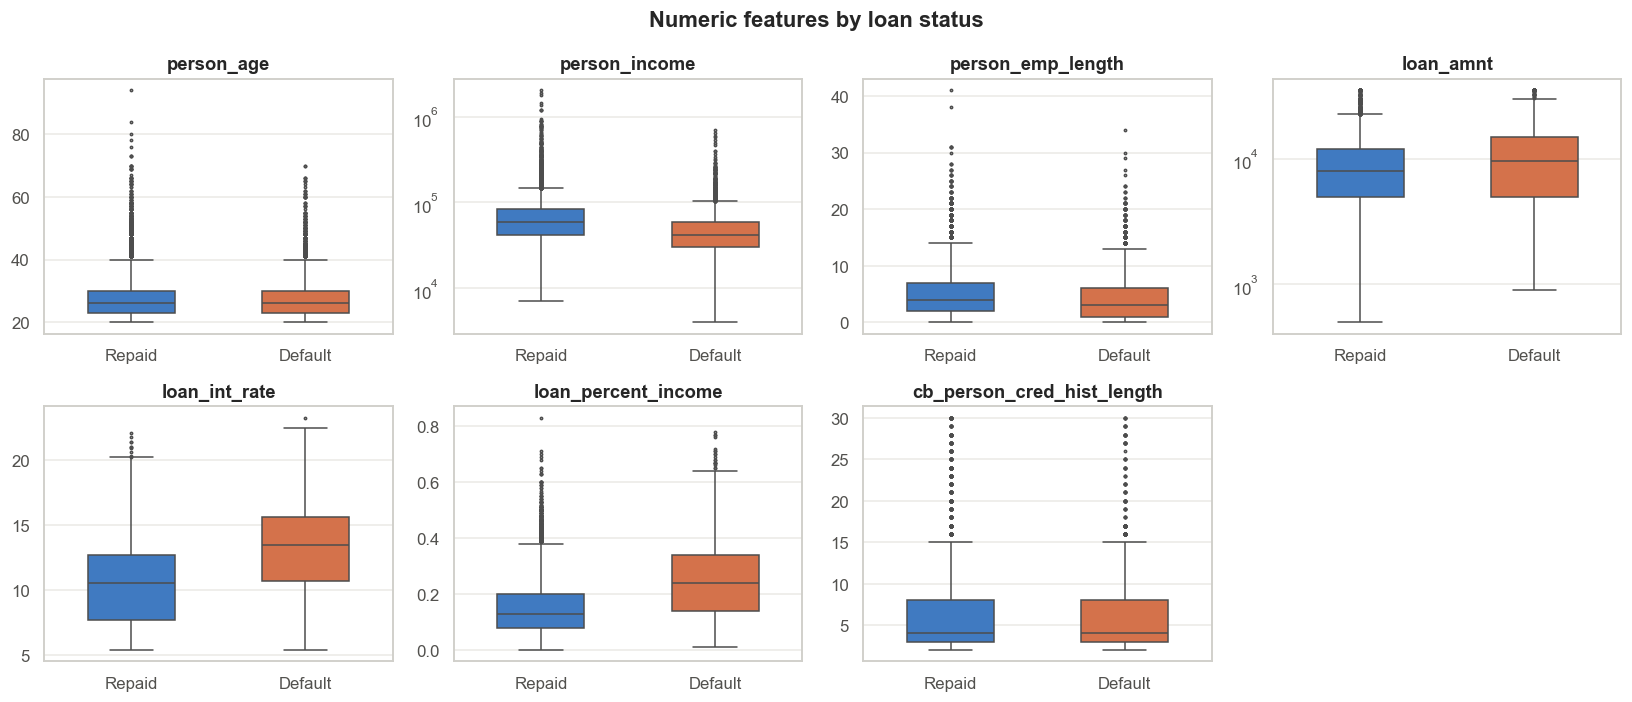

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
palette = {str(k): v for k, v in STATUS_COLORS.items()}
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df.assign(loan_status=df.loan_status.astype(str)), x="loan_status", y=col,
                hue="loan_status", palette=palette, ax=ax, width=0.5, linewidth=1,
                fliersize=1.5, legend=False)
    if col in log_cols:
        ax.set_yscale("log")
    ax.set_xticks([0, 1], ["Repaid", "Default"])
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(num_cols):]:
    ax.remove()
fig.suptitle("Numeric features by loan status", fontweight="bold")
plt.tight_layout(); plt.show()

### 5.4 Default rate by categorical feature
The dashed line is the overall default rate.

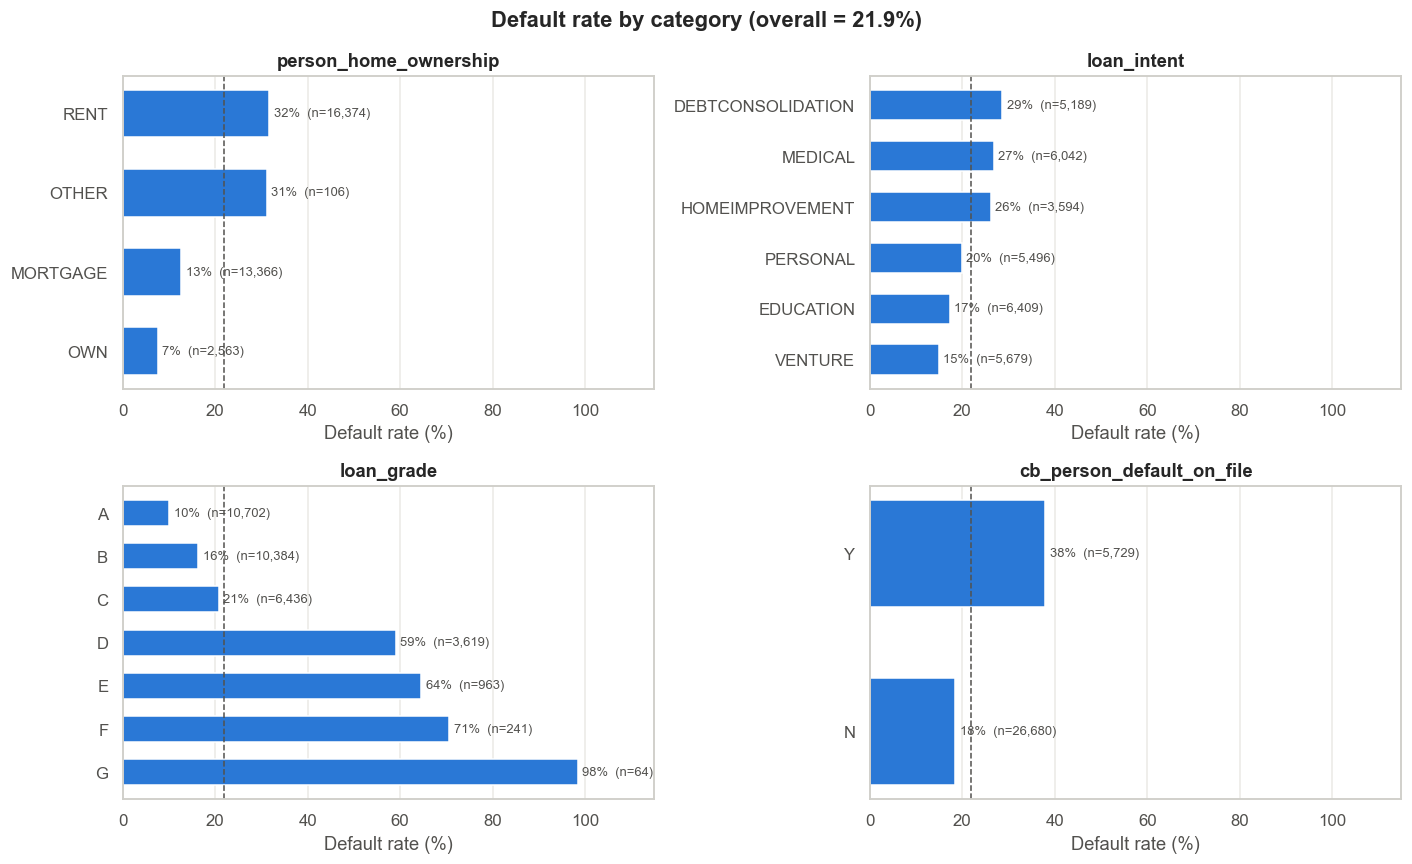

In [21]:
overall = df.loan_status.mean()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col).loan_status.agg(["mean", "size"])
    rate = rate.sort_index() if col == "loan_grade" else rate.sort_values("mean")
    ax.barh(rate.index.astype(str), rate["mean"] * 100, color=BLUE, height=0.6)
    for y, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(m * 100 + 1, y, f"{m:.0%}  (n={n:,})", va="center", color=GRAY, fontsize=8.5)
    ax.axvline(overall * 100, color=GRAY, ls="--", lw=1)
    ax.set_xlim(0, 115); ax.set_xlabel("Default rate (%)")
    ax.set_title(col); ax.grid(axis="y", visible=False)
    if col == "loan_grade":
        ax.invert_yaxis()
fig.suptitle(f"Default rate by category (overall = {overall:.1%})", fontweight="bold")
plt.tight_layout(); plt.show()

### 5.5 Default rate across numeric bins

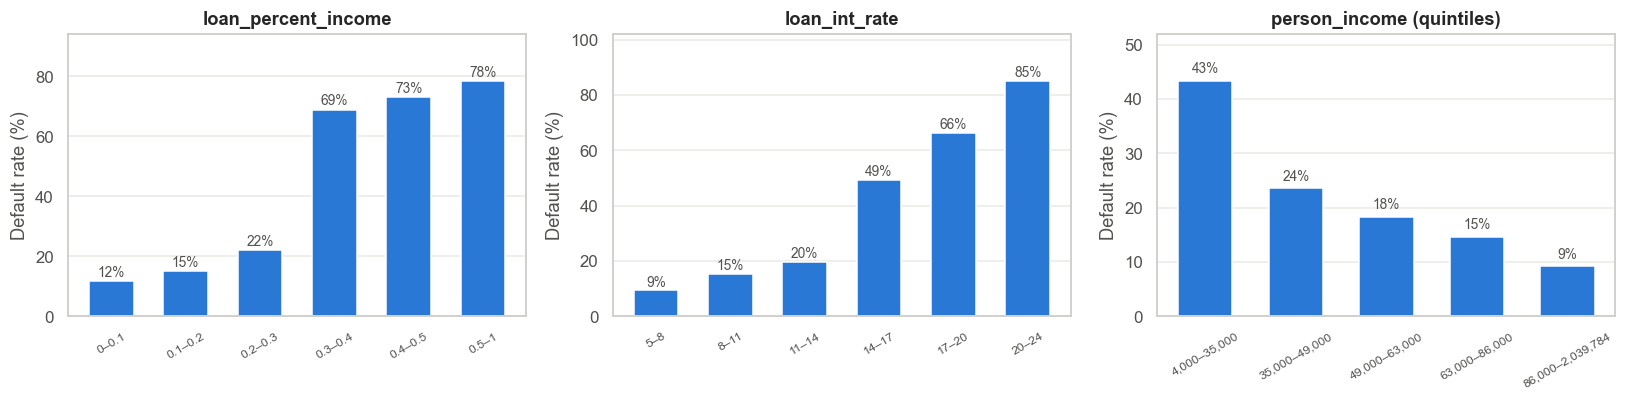

In [22]:
binned = {
    "loan_percent_income": pd.cut(df.loan_percent_income, [0, .1, .2, .3, .4, .5, 1]),
    "loan_int_rate": pd.cut(df.loan_int_rate, [5, 8, 11, 14, 17, 20, 24]),
    "person_income": pd.qcut(df.person_income, 5),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, bins) in zip(axes, binned.items()):
    rate = df.groupby(bins, observed=True).loan_status.mean() * 100
    labels = [f"{b.left:,.0f}–{b.right:,.0f}" if col == "person_income" else f"{b.left:g}–{b.right:g}"
              for b in rate.index]
    ax.bar(labels, rate.values, color=BLUE, width=0.6)
    for x, v in enumerate(rate.values):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", color=GRAY, fontsize=9)
    ax.set_ylim(0, max(rate.max() * 1.2, 10)); ax.set_ylabel("Default rate (%)")
    ax.set_title(col + (" (quintiles)" if col == "person_income" else ""))
    ax.tick_params(axis="x", rotation=30, labelsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 5.6 Correlation heatmap (Spearman)

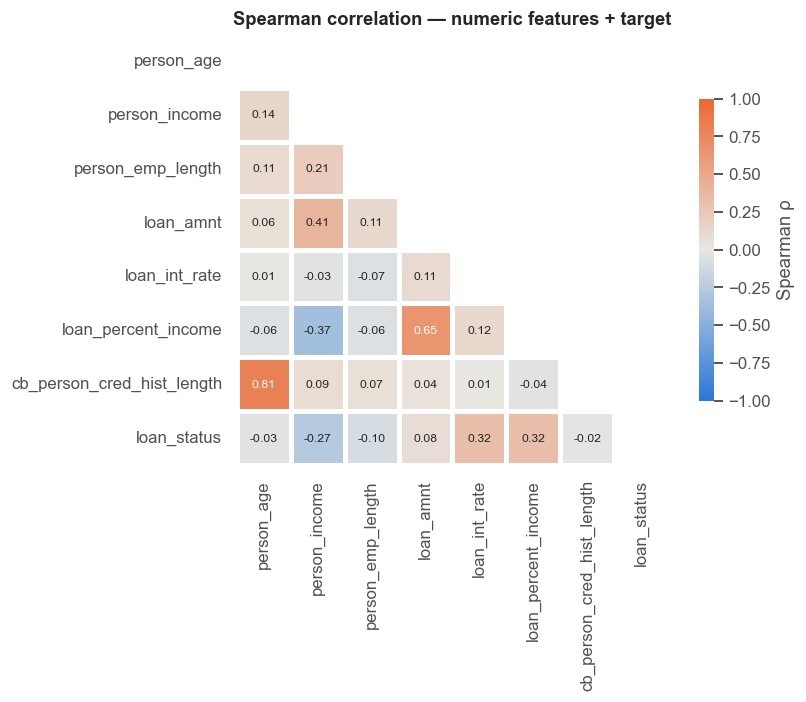

In [23]:
fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=2, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlation — numeric features + target")
ax.grid(False)
plt.tight_layout(); plt.show()

### 5.7 Loan grade vs interest rate

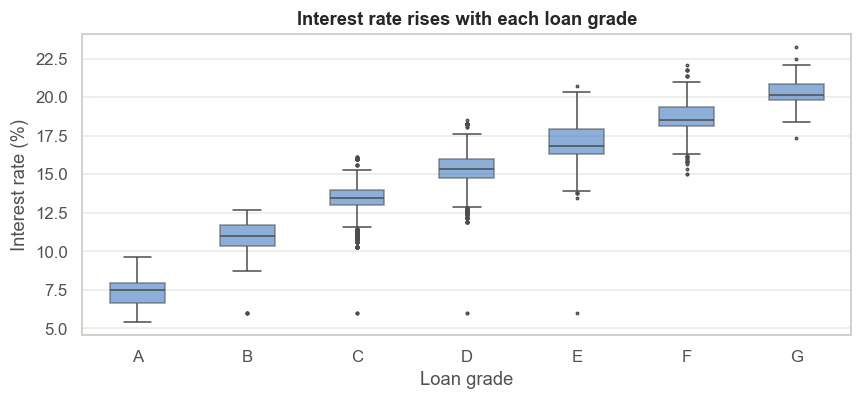

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=df, x="loan_grade", y="loan_int_rate", order=sorted(df.loan_grade.unique()),
            color=BLUE, width=0.5, linewidth=1, fliersize=1.5, boxprops={"alpha": 0.6}, ax=ax)
ax.set_title("Interest rate rises with each loan grade"); ax.set_xlabel("Loan grade"); ax.set_ylabel("Interest rate (%)")
plt.tight_layout(); plt.show()

## 6. Key findings

**Data quality**
- 32,581 rows × 12 columns. Missing values in only two columns: `loan_int_rate` (9.6%) and `person_emp_length` (2.7%).
- Missing `person_emp_length` is **not random**: those applicants default at ~32% vs ~22% — worth a "missing" indicator flag when modelling.
- 165 exact duplicate rows and 7 rows with impossible values (age 123/144, employment length 123 years) were removed → 32,409 rows.
- `person_income` is extremely right-skewed (skew ≈ 9.8) — use a log transform for modelling.

**Target**
- Imbalanced: ~78% repaid vs ~22% default. Use stratified splits and look at recall / PR-AUC, not just accuracy.

**Strongest signals of default** (all p < 0.001)
- **Loan grade** (Cramér's V ≈ 0.42): default rate climbs from 10% (A) to 59% (D) and 98% (G).
- **Interest rate** and **loan-to-income ratio** (rank-biserial r ≈ 0.45 each): when the loan is over 30% of income, the default rate jumps to roughly 70%.
- **Income** (r ≈ −0.38): the lowest income quintile defaults at 43%, the highest at 9%.
- **Home ownership**: renters default at 32%, owners at 7%.
- **Prior default on file**: 38% vs 18%.
- Age and credit-history length have almost no relationship with default.

**Watch-outs for modelling**
- `person_age` and `cb_person_cred_hist_length` are strongly correlated (ρ ≈ 0.81); so are `loan_amnt` and `loan_percent_income` (ρ ≈ 0.65).
- `loan_int_rate` is largely set by `loan_grade`, so the two carry overlapping information.